In [3]:
import glob
import random
import numpy as np

from tf_unet import unet
from tf_unet import image_util

from skimage import io, transform
from corebreakout.segmentation.utils import crop_tray_cols, mirror_pad

In [4]:
dbox_path = '/home/administrator/Dropbox/core_data'
model_path = dbox_path+'/saved_models/unet/'             # for saved model ckpts
royal_path = dbox_path+'/well_core_data/wos_data/schiehallion-complex/204-19-6/converted/'

In [5]:
model = unet.Unet(channels=3, n_class=2, layers=5, features_root=32)

path = model_path + 'l5_f32_d0.75_w0.6_cols/model.ckpt'

2018-07-23 14:07:50,802 Layers 5, features 32, filter size 3x3, pool size: 2x2


In [57]:
def preproc_img(img):
    img = transform.rescale(img, 0.25)
    print(img.shape)
    img = mirror_pad(img, (img.shape[0]+191, img.shape[1]+191))
    return img

def pred_and_thresh(img, threshold):
    pred = model.predict(path, img[np.newaxis,...])
    diff = pred[0,...,1]-pred[0,...,0]
    return diff, diff>threshold

In [7]:
img_files = sorted(glob.glob(royal_path+'*jpeg'))
img_files

['/home/administrator/Dropbox/core_data/well_core_data/wos_data/schiehallion-complex/204-19-6/converted/S00111577.jpeg',
 '/home/administrator/Dropbox/core_data/well_core_data/wos_data/schiehallion-complex/204-19-6/converted/S00111578.jpeg',
 '/home/administrator/Dropbox/core_data/well_core_data/wos_data/schiehallion-complex/204-19-6/converted/S00111579.jpeg',
 '/home/administrator/Dropbox/core_data/well_core_data/wos_data/schiehallion-complex/204-19-6/converted/S00111580.jpeg',
 '/home/administrator/Dropbox/core_data/well_core_data/wos_data/schiehallion-complex/204-19-6/converted/S00111581.jpeg',
 '/home/administrator/Dropbox/core_data/well_core_data/wos_data/schiehallion-complex/204-19-6/converted/S00111582.jpeg',
 '/home/administrator/Dropbox/core_data/well_core_data/wos_data/schiehallion-complex/204-19-6/converted/S00111583.jpeg']

In [8]:
imgs = [io.imread(f) for f in img_files]

In [10]:
colgroups = [crop_tray_cols(img, 'A')[0:2] for img in imgs]

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/transform/_warps.py:24: UserWarning: The default multichannel argument (None) is deprecated.  Please specify either True or False explicitly.  multichannel will default to False starting with release 0.16.
  warn('The default multichannel argument (None) is deprecated.  Please '
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/transform/_warps.py:105: UserWarning: The default mode, 'constant', will be changed to 'reflect' in skimage 0.15.
  warn("The default mode, 'constant', will be changed to 'reflect' in "
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/transform/_warps.py:110: UserWarning: Anti-aliasing will be enabled by default in skimage 0.15 to avoid aliasing artifacts when down-sampling images.
  warn("Anti-aliasing will be enabled by default in skimage 0.15 to "


(269, 1600, 3)
INFO:tensorflow:Restoring parameters from /home/administrator/Dropbox/core_data/saved_models/unet/l5_f32_d0.75_w0.6_cols/model.ckpt


2018-07-23 14:25:31,315 Restoring parameters from /home/administrator/Dropbox/core_data/saved_models/unet/l5_f32_d0.75_w0.6_cols/model.ckpt
2018-07-23 14:25:31,389 Model restored from file: /home/administrator/Dropbox/core_data/saved_models/unet/l5_f32_d0.75_w0.6_cols/model.ckpt


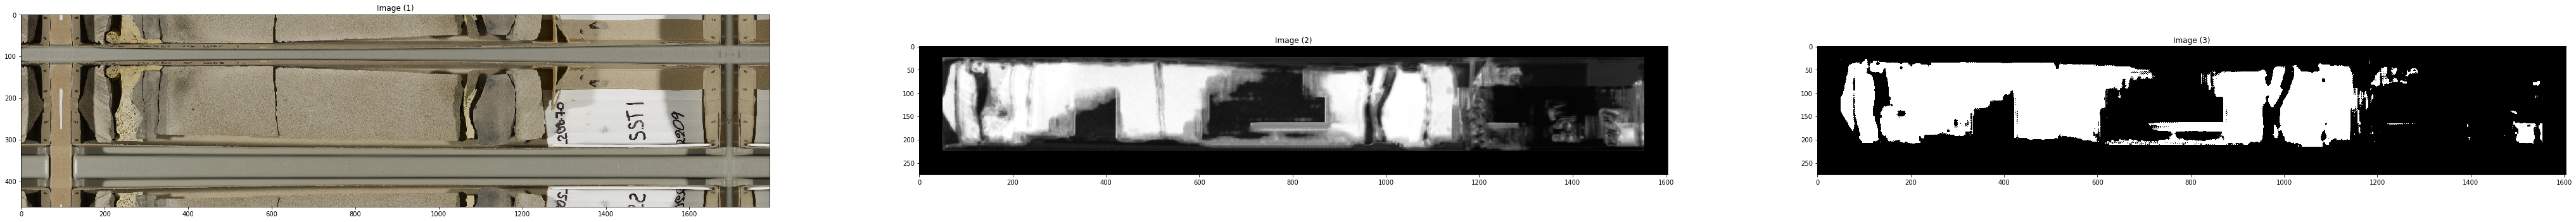

(276, 1604)


In [37]:
from corebreakout.utils.viz_utils import show_images

in_col = preproc_img(colgroups[0][0])

pred, classes = pred_and_thresh(in_col, -0.0)

show_images([in_col, pred, classes])

print(pred.shape)

In [58]:
from corebreakout.utils.viz_utils import show_images

thresh = -0.1

out_cols = []
out_preds = []
out_classes = []
for fname, img, colset in zip(img_files, imgs, colgroups):
    print("Showing: ", fname.split('/')[0])
    #show_images([img])
    #print('Column preds: ')
    for col in colset:
        preds, classes = pred_and_thresh(preproc_img(col), thresh)
        out_cols.append(transform.rescale(col, 0.25)[25:-50,50:-50])
        out_preds.append(preds[25:-50,50:-50])
        out_classes.append(classes[25:-50,50:-50])
        
c = np.concatenate(out_cols, axis=1)
p = np.concatenate(out_preds, axis=1)
l = np.concatenate(out_classes, axis=1)

Showing:  
(269, 1600, 3)


/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/transform/_warps.py:24: UserWarning: The default multichannel argument (None) is deprecated.  Please specify either True or False explicitly.  multichannel will default to False starting with release 0.16.
  warn('The default multichannel argument (None) is deprecated.  Please '
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/transform/_warps.py:105: UserWarning: The default mode, 'constant', will be changed to 'reflect' in skimage 0.15.
  warn("The default mode, 'constant', will be changed to 'reflect' in "
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/transform/_warps.py:110: UserWarning: Anti-aliasing will be enabled by default in skimage 0.15 to avoid aliasing artifacts when down-sampling images.
  warn("Anti-aliasing will be enabled by default in skimage 0.15 to "


INFO:tensorflow:Restoring parameters from /home/administrator/Dropbox/core_data/saved_models/unet/l5_f32_d0.75_w0.6_cols/model.ckpt


2018-07-23 14:45:59,057 Restoring parameters from /home/administrator/Dropbox/core_data/saved_models/unet/l5_f32_d0.75_w0.6_cols/model.ckpt
2018-07-23 14:45:59,256 Model restored from file: /home/administrator/Dropbox/core_data/saved_models/unet/l5_f32_d0.75_w0.6_cols/model.ckpt


(269, 1600, 3)
INFO:tensorflow:Restoring parameters from /home/administrator/Dropbox/core_data/saved_models/unet/l5_f32_d0.75_w0.6_cols/model.ckpt


...

2018-07-23 14:46:11,846 Restoring parameters from /home/administrator/Dropbox/core_data/saved_models/unet/l5_f32_d0.75_w0.6_cols/model.ckpt
2018-07-23 14:46:12,040 Model restored from file: /home/administrator/Dropbox/core_data/saved_models/unet/l5_f32_d0.75_w0.6_cols/model.ckpt


Showing:  
(269, 1600, 3)
INFO:tensorflow:Restoring parameters from /home/administrator/Dropbox/core_data/saved_models/unet/l5_f32_d0.75_w0.6_cols/model.ckpt


2018-07-23 14:46:12,964 Restoring parameters from /home/administrator/Dropbox/core_data/saved_models/unet/l5_f32_d0.75_w0.6_cols/model.ckpt
2018-07-23 14:46:13,159 Model restored from file: /home/administrator/Dropbox/core_data/saved_models/unet/l5_f32_d0.75_w0.6_cols/model.ckpt


(269, 1600, 3)
INFO:tensorflow:Restoring parameters from /home/administrator/Dropbox/core_data/saved_models/unet/l5_f32_d0.75_w0.6_cols/model.ckpt


2018-07-23 14:46:14,102 Restoring parameters from /home/administrator/Dropbox/core_data/saved_models/unet/l5_f32_d0.75_w0.6_cols/model.ckpt
2018-07-23 14:46:14,304 Model restored from file: /home/administrator/Dropbox/core_data/saved_models/unet/l5_f32_d0.75_w0.6_cols/model.ckpt


In [59]:
c.shape, p.shape, l.shape

((194, 21000, 3), (201, 21056), (201, 21056))

In [63]:
io.imsave(dbox_path+'/example_col.jpg', np.rot90(c, 3))
io.imsave(dbox_path+'/example_preds.jpg', np.rot90(p, 3))
io.imsave(dbox_path+'/example_label.jpg', np.rot90(l.astype(int), 3)*255)

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/util/dtype.py:130: UserWarning: Possible precision loss when converting from float64 to uint8
  .format(dtypeobj_in, dtypeobj_out))
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/util/dtype.py:130: UserWarning: Possible precision loss when converting from float32 to uint8
  .format(dtypeobj_in, dtypeobj_out))
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:140: UserWarning: /home/administrator/Dropbox/core_data/example_label.jpg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/util/dtype.py:126: UserWarning: Possible sign loss when converting negative image of type int64 to positive image of type uint8.
  .format(dtypeobj_in, dtypeobj_out))
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/util/dtype.py:17

In [ ]:
show_images(imgs[0])